# Result analysis: geometry-to-topology model ladder

Validation-only analysis of final cached predictions. Follow the **Controlled model ladder** in `../project_plan_contract_groupID07.pdf`: Stage 1 geometry; Stage 1.5 shallow topology; Stage 2a frozen geometry + GCN; Stage 2b joint geometry + GCN; Stage 3 edge conditioning. No training or inference is performed, and the test split is not read.

For shallow topology, use only the **frozen FaceCNN** with the smaller completed configuration: Laplacian k=8, WL T=3 (rather than 4), graphlets up to 4 nodes (rather than 5). These three are **parallel alternatives at Stage 1.5**, not features stacked on one another. Use 2-hop Chebyshev GCN in both frozen and joint modes. Stage 3 contains joint FaceCNN + static/updated edge states, each with two message-passing layers and a learned EdgeCNN. These are the course-style GatedGCN adaptation, not an exact reproduction of the plan's full UV-Net architecture.

Metrics are recomputed from aligned validation labels and predictions: micro face accuracy and **unweighted mean class IoU**, including stock; classes with zero union are undefined and omitted from the mean. Representative runs are selected by these fixed settings, not by choosing the best validation score. All are epoch 20, single-run results.

In [1]:
from pathlib import Path
import hashlib
import json

import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

# Works when launched from the project root or notebooks directory.
project_dir = next(path for path in (Path.cwd(), *Path.cwd().parents)
                   if (path / "data/MFCADDataset/split.json").is_file()
                   and (path / "results").is_dir())
data_dir = project_dir / "data/MFCADDataset"
output_dir = project_dir / "results/result_analysis"
output_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

# Order follows the project plan; the three Stage 1.5 rows are alternatives.
model_specs = [
    ("1", "Geometry", "baseline_run_01", "Face CNN + independent classifier"),
    ("1.5", "Laplacian", "laplacian_run_01", "Frozen CNN + 8 Laplacian coordinates"),
    ("1.5", "WL (T=3)", "wl3_frozen_run_01", "Frozen CNN + WL rounds 0–3"),
    ("1.5", "Graphlets (≤4)", "graphlet4_frozen_run_01", "Frozen CNN + 2–4 node graphlets"),
    ("2a", "GCN frozen", "cheb2_frozen_run_01", "Frozen CNN + degree-2 Chebyshev filter"),
    ("2b", "GCN joint", "cheb2_joint_run_01", "Joint CNN + degree-2 Chebyshev filter"),
    ("3a", "Edge static", "anisotropic_static_joint_run_01", "Joint FaceCNN + static encoded edge state, 2 layers"),
    ("3b", "Edge updated", "anisotropic_updated_joint_run_01", "Joint FaceCNN + updated edge state, 2 layers"),
]
selection = pd.DataFrame(model_specs, columns=["stage", "model", "run", "configuration"])
model_order = selection["model"].tolist()
display(selection.set_index(["stage", "model"])[["configuration", "run"]])

Matplotlib created a temporary config/cache directory at /var/folders/j5/3__09qbn23992bj8tqg6vyvr0000gn/T/matplotlib-bx0nbz8y because the default path (/Users/yongjun/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.



Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig
	/Users/yongjun/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig
	/Users/yongjun/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig
	/Users/yongjun/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig
	/Users/yongjun/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig
	/Users/yongjun/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig
	/Users/yongjun/.fontconfig

Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/yongjun/.cache/fontconfig

configuration  \
stage model                                                               
1     Geometry                        Face CNN + independent classifier   
1.5   Laplacian                    Frozen CNN + 8 Laplacian coordinates   
      WL (T=3)                               Frozen CNN + WL rounds 0–3   
      Graphlets (≤4)                    Frozen CNN + 2–4 node graphlets   
2a    GCN frozen                 Frozen CNN + degree-2 Chebyshev filter   
2b    GCN joint                   Joint CNN + degree-2 Chebyshev filter   
3a    Edge static     Joint FaceCNN + static encoded edge state, 2 l...   
3b    Edge updated         Joint FaceCNN + updated edge state, 2 layers   

                                                   run  
stage model                                             
1     Geometry                         baseline_run_01  
1.5   Laplacian                       laplacian_run_01  
      WL (T=3)                       wl3_frozen_run_01  
      Graphlets (≤4)           graphlet4_frozen_run_01  
2a    GCN frozen                   cheb2_frozen_run_01  
2b    GCN joint                     cheb2_joint_run_01  
3a    Edge static      anisotropic_static_joint_run_01  
3b    Edge updated    anisotropic_updated_joint_run_01

## Load final validation predictions and verify row identity

Require the same validation solid order, per-row solid indices, graph face indices and true labels for every model. Rebuild the reference labels from the local validation annotations. A row is identified by `(sample_id, face_index)`; the face index is a zero-based graph node/annotation position, not a STEP viewer identifier. Missing files or inconsistent order stop the analysis rather than silently dropping a rung.

In [2]:
split_ids = json.loads((data_dir / "split.json").read_text())["validation"]
reference_labels, face_counts, class_names = [], [], {}
for sample_id in split_ids:
    faces = json.loads((data_dir / "labels" / f"{sample_id}_ids.json").read_text())["body"]["faces"]
    face_counts.append(len(faces))
    for face in faces:
        segment = face["segment"]
        index, name = segment["index"], segment["name"]
        if index in class_names and class_names[index] != name:
            raise ValueError(f"Conflicting class name for index {index}")
        class_names[index] = name
        reference_labels.append(index)
reference_labels = torch.tensor(reference_labels, dtype=torch.long)
counts = torch.tensor(face_counts, dtype=torch.long)
reference_offsets = torch.cat((torch.zeros(1, dtype=torch.long), counts.cumsum(0)))
reference_samples = torch.repeat_interleave(torch.arange(len(split_ids)), counts)
reference_faces = torch.arange(len(reference_labels)) - reference_offsets[reference_samples]
num_classes = len(class_names)
assert sorted(class_names) == list(range(num_classes))

cached, provenance = {}, []
for stage, model_name, run, configuration in model_specs:
    path = project_dir / "results" / run / "epoch_020/validation_predictions.pt"
    result = torch.load(path, map_location="cpu", weights_only=True)
    assert result["index_format_version"] == 1 and result["split"] == "validation", model_name
    assert result["sample_ids"] == split_ids, model_name
    for key, expected in (("labels", reference_labels), ("sample_indices", reference_samples),
                          ("face_indices", reference_faces), ("sample_offsets", reference_offsets)):
        assert torch.equal(result[key], expected), (model_name, key)
    assert result["probabilities"].shape == (len(reference_labels), num_classes), model_name
    assert torch.isfinite(result["probabilities"]).all(), model_name
    assert torch.equal(result["predictions"], result["probabilities"].argmax(1)), model_name
    cached[model_name] = result
    provenance.append(dict(stage=stage, model=model_name, run=run, epoch=20,
                           prediction_file=str(path.relative_to(project_dir)),
                           sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
(output_dir / "selected_inputs.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Aligned {len(cached)} models: {len(split_ids):,} validation solids, "
      f"{len(reference_labels):,} faces, {num_classes} classes.")

Aligned 8 models: 3,090 validation solids, 70,255 faces, 16 classes.


/Users/yongjun/miniconda3/envs/gnn_project/lib/python3.11/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## Consolidated validation accuracy and mean IoU

Compute each confusion matrix over the entire validation split, with rows=true and columns=predicted. Accuracy is total correct / total faces. Per-class IoU is TP / (TP + FP + FN); mean IoU gives each class equal weight. `gain_vs_geometry_pp` measures absolute percentage-point improvement over the baseline, not a relative percentage increase.

In [3]:
summary_rows, class_rows, confusion_matrices = [], [], {}
for stage, model_name, run, configuration in model_specs:
    result = cached[model_name]
    labels, predictions = result["labels"].long(), result["predictions"].long()
    confusion = torch.bincount(labels * num_classes + predictions,
                              minlength=num_classes ** 2).reshape(num_classes, num_classes)
    confusion_matrices[model_name] = confusion
    tp = confusion.diag()
    support, predicted_support = confusion.sum(1), confusion.sum(0)
    fn, fp = support - tp, predicted_support - tp
    union = tp + fn + fp
    iou = tp.double() / union.double().masked_fill(union == 0, float("nan"))
    recall = tp.double() / support.double().masked_fill(support == 0, float("nan"))
    accuracy = tp.sum().item() / labels.numel()
    # Cached scalar accuracy is float32 in the original evaluator.
    assert abs(accuracy - result["accuracy"]) < 1e-6, model_name
    assert torch.equal(confusion, result["confusion_matrix"]), model_name
    summary_rows.append(dict(stage=stage, model=model_name, epoch=20,
                             validation_faces=len(labels), loss=result["loss"],
                             accuracy=accuracy, mean_iou=iou.nanmean().item(),
                             misclassified_faces=fn.sum().item()))
    for class_index in range(num_classes):
        class_rows.append(dict(stage=stage, model=model_name, class_index=class_index,
                               class_name=class_names[class_index], support=support[class_index].item(),
                               true_positive=tp[class_index].item(), false_negative=fn[class_index].item(),
                               false_positive=fp[class_index].item(), iou=iou[class_index].item(),
                               recall=recall[class_index].item()))
summary = pd.DataFrame(summary_rows).set_index("model").loc[model_order]
class_metrics = pd.DataFrame(class_rows)
summary["gain_vs_geometry_pp"] = 100 * (summary["mean_iou"] - summary.loc["Geometry", "mean_iou"])
display(summary.style.format({"loss": "{:.5f}", "accuracy": "{:.2%}", "mean_iou": "{:.2%}",
                               "gain_vs_geometry_pp": "{:+.2f}"}))
summary.to_csv(output_dir / "validation_summary.csv")
class_metrics.to_csv(output_dir / "validation_class_metrics.csv", index=False)

,stage,epoch,validation_faces,loss,accuracy,mean_iou,misclassified_faces,gain_vs_geometry_pp
model,,,,,,,,
Geometry,1,20,70255,0.28625,89.44%,79.42%,7420,+0.00
Laplacian,1.5,20,70255,0.24979,90.97%,82.39%,6344,+2.97
WL (T=3),1.5,20,70255,0.11714,95.66%,90.32%,3050,+10.90
Graphlets (≤4),1.5,20,70255,0.09446,96.55%,92.33%,2425,+12.91
GCN frozen,2a,20,70255,0.02631,99.09%,98.21%,637,+18.79
GCN joint,2b,20,70255,0.01556,99.51%,98.93%,342,+19.51
Edge static,3a,20,70255,0.00159,99.95%,99.87%,37,+20.45
Edge updated,3b,20,70255,0.00082,99.97%,99.93%,18,+20.51


## Overall performance chart

Show both validation accuracy and mean IoU on a common 0–100% scale. The shaded group contains the three Stage 1.5 alternatives. The x-axis is the plan's model order; adjacent shallow models are not cumulative training stages.

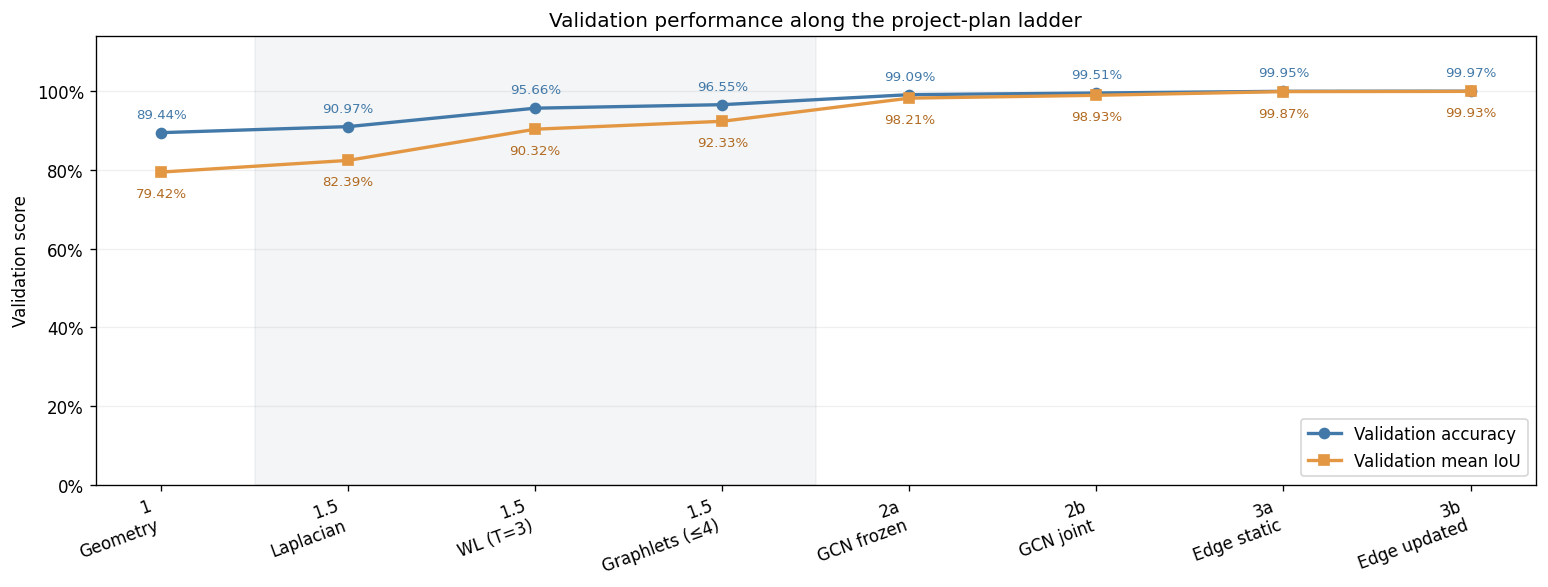

In [4]:
x = list(range(len(model_order)))
axis_labels = [f"{stage}\n{model}" for stage, model, _, _ in model_specs]
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(x, summary["accuracy"], marker="o", linewidth=2,
        label="Validation accuracy", color="#4279a8")
ax.plot(x, summary["mean_iou"], marker="s", linewidth=2,
        label="Validation mean IoU", color="#e39743")
ax.axvspan(0.5, 3.5, color="#718096", alpha=0.08, zorder=0)
for i, accuracy, iou in zip(x, summary["accuracy"], summary["mean_iou"]):
    ax.annotate(f"{accuracy:.2%}", (i, accuracy), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=8, color="#4279a8")
    ax.annotate(f"{iou:.2%}", (i, iou), xytext=(0, -15),
                textcoords="offset points", ha="center", fontsize=8, color="#b16a21")
ax.set_xticks(x, axis_labels, rotation=20, ha="right")
ax.set_ylim(0, 1.14)
ax.set_yticks([0, .2, .4, .6, .8, 1.0])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("Validation score")
ax.set_title("Validation performance along the project-plan ladder")
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(output_dir / "validation_model_ladder.png", dpi=180, bbox_inches="tight")
plt.show()

## Class breakdown: representative models at each rung

Show all validation classes, with support and the baseline's false negatives (true faces classified incorrectly). The first table reports **IoU**; the second reports **per-class recall** (correct faces / true faces of that class, also called class accuracy). Stock is retained. This avoids confusing recall with IoU, which also penalizes false positives.

Heatmap colours span the observed minimum and maximum of each metric table, with a shared scale across all model columns. Lower scores are cream and higher scores blue.


In [5]:
from matplotlib.colors import LinearSegmentedColormap

table_cmap = LinearSegmentedColormap.from_list("table_two_tone", ["#fff1de", "#266b8e"])

baseline_classes = class_metrics[class_metrics["model"] == "Geometry"].set_index("class_index").sort_index()
class_info = baseline_classes[["class_name", "support", "false_negative"]].rename(
    columns={"support": "validation_faces", "false_negative": "baseline_missed_faces"})
iou_table = class_metrics.pivot(index="class_index", columns="model", values="iou").reindex(columns=model_order)
recall_table = class_metrics.pivot(index="class_index", columns="model", values="recall").reindex(columns=model_order)
class_iou_table = class_info.join(iou_table)
class_recall_table = class_info.join(recall_table)
print("Validation IoU by class:")
display(class_iou_table.style.format({name: "{:.2%}" for name in model_order})
        .background_gradient(cmap=table_cmap, subset=model_order, axis=None,
                             vmin=iou_table.min().min(), vmax=iou_table.max().max()))
print("Validation recall / class accuracy:")
display(class_recall_table.style.format({name: "{:.2%}" for name in model_order})
        .background_gradient(cmap=table_cmap, subset=model_order, axis=None,
                             vmin=recall_table.min().min(), vmax=recall_table.max().max()))
class_iou_table.to_csv(output_dir / "validation_class_iou.csv")
class_recall_table.to_csv(output_dir / "validation_class_recall.csv")

Validation IoU by class:


,class_name,validation_faces,baseline_missed_faces,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
class_index,,,,,,,,,,,
0,rectangular_through_slot,924,5,99.46%,99.78%,99.68%,99.46%,100.00%,99.57%,99.89%,99.78%
1,triangular_through_slot,2985,1245,49.36%,60.25%,66.62%,96.47%,84.82%,91.73%,99.23%,99.77%
2,rectangular_passage,4390,805,70.35%,72.56%,78.45%,82.66%,96.61%,97.48%,99.34%,99.70%
3,triangular_passage,6804,763,76.05%,80.24%,85.64%,93.81%,93.21%,96.96%,99.85%,99.91%
4,6sides_passage,1892,1,99.42%,99.53%,99.53%,99.58%,100.00%,99.89%,100.00%,99.95%
5,rectangular_through_step,2883,606,71.27%,72.31%,72.35%,76.63%,99.76%,99.69%,100.00%,100.00%
6,2sides_through_step,1804,258,78.56%,82.90%,85.31%,86.43%,99.61%,99.83%,100.00%,100.00%
7,slanted_through_step,2730,3,95.55%,99.27%,99.93%,99.27%,99.93%,99.96%,99.96%,99.96%
8,rectangular_blind_step,1660,49,93.88%,98.62%,99.16%,99.28%,99.88%,99.76%,99.94%,99.94%


Validation recall / class accuracy:


,class_name,validation_faces,baseline_missed_faces,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
class_index,,,,,,,,,,,
0,rectangular_through_slot,924,5,99.46%,99.78%,99.68%,99.68%,100.00%,99.68%,99.89%,99.78%
1,triangular_through_slot,2985,1245,58.29%,73.77%,77.29%,97.96%,96.78%,93.70%,99.80%,99.97%
2,rectangular_passage,4390,805,81.66%,84.33%,87.74%,91.34%,97.43%,98.56%,99.36%,99.73%
3,triangular_passage,6804,763,88.79%,87.70%,93.90%,95.74%,94.59%,99.49%,99.99%,99.97%
4,6sides_passage,1892,1,99.95%,99.84%,99.79%,99.84%,100.00%,100.00%,100.00%,100.00%
5,rectangular_through_step,2883,606,78.98%,78.63%,83.04%,84.50%,99.93%,99.83%,100.00%,100.00%
6,2sides_through_step,1804,258,85.70%,91.13%,92.07%,91.08%,99.72%,99.83%,100.00%,100.00%
7,slanted_through_step,2730,3,99.89%,99.63%,99.96%,99.60%,99.96%,100.00%,100.00%,100.00%
8,rectangular_blind_step,1660,49,97.05%,99.22%,99.64%,99.58%,99.88%,99.82%,99.94%,99.94%


## Follow the baseline's five hardest classes by IoU

Rank classes **once using baseline validation IoU**, ascending (lowest first); break ties by class index. Display support, missed faces, error rate and false positives as context. Every top-five selection in this notebook uses this same baseline-IoU ranking. Keep these same five classes for every rung; do not select different classes based on later results.

Plot their absolute IoU and change from their own baseline IoU in percentage points. Stage 1.5 remains three alternatives; later models may improve or regress, so the charts do not assume monotonic gains.

,class_index,class_name,support,false_negative,false_positive,error_rate,iou
1,1,triangular_through_slot,2985,1245,540,41.71%,49.36%
12,12,triangular_pocket,3816,975,896,25.55%,60.29%
9,9,triangular_blind_step,3828,859,910,22.44%,62.66%
14,14,chamfer,2763,746,370,27.00%,64.38%
2,2,rectangular_passage,4390,805,706,18.34%,70.35%


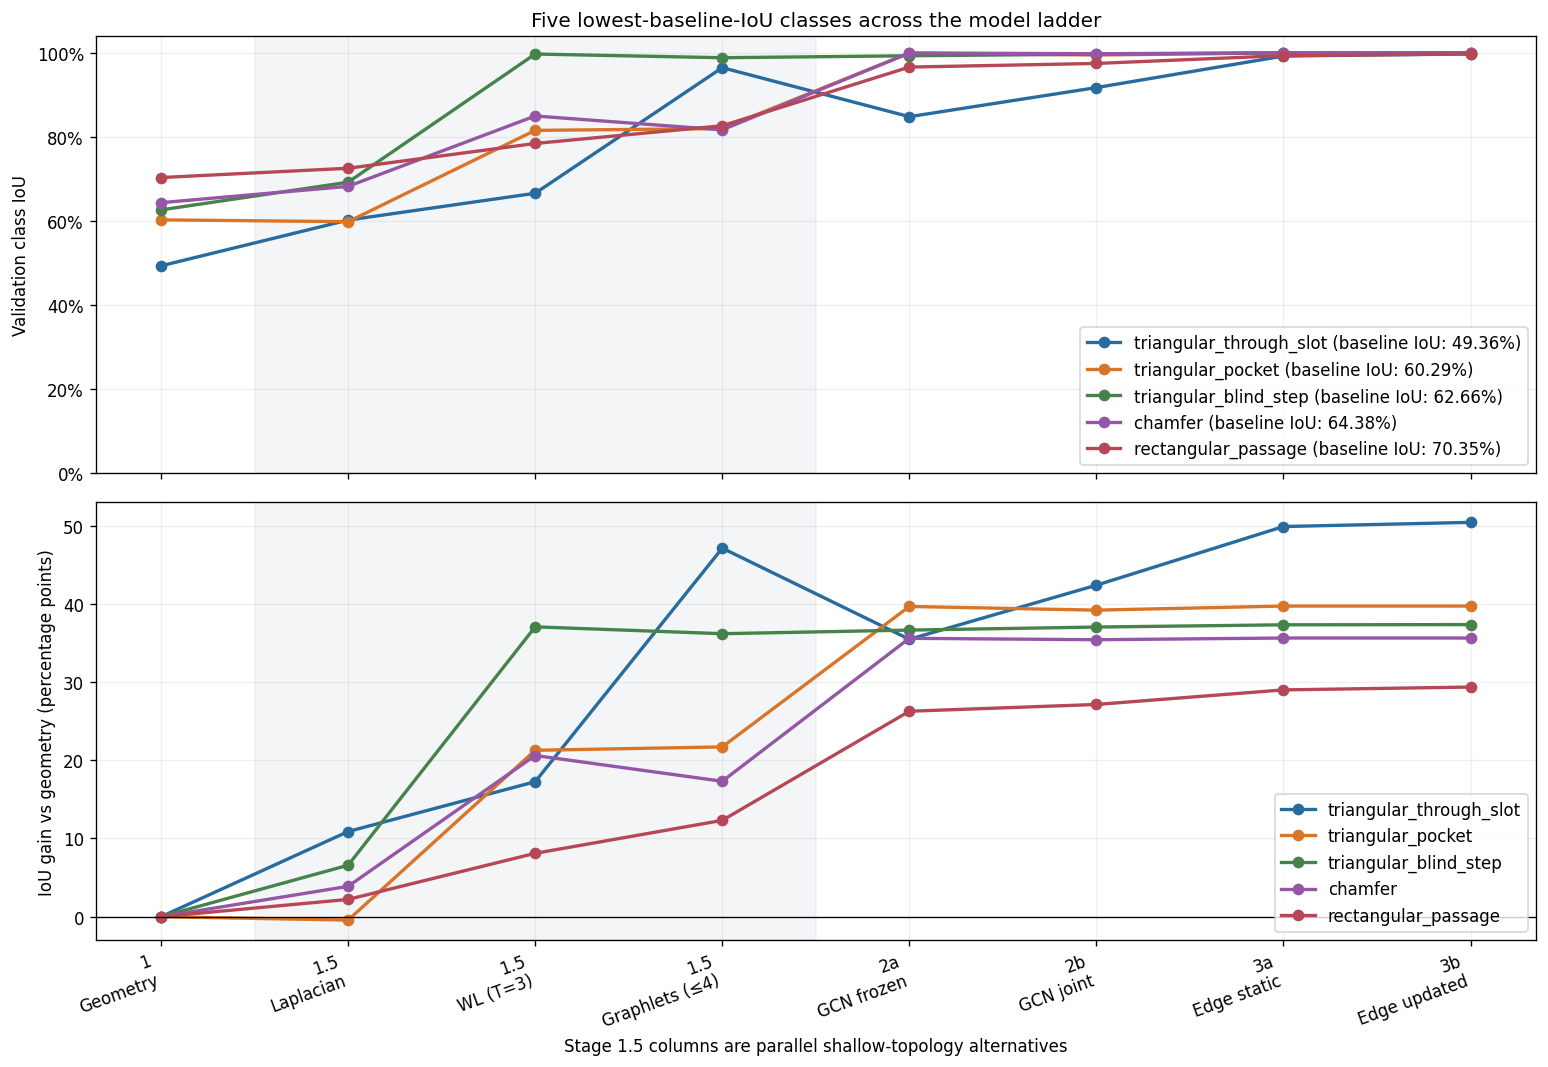

,model,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
class_index,class_name,,,,,,,,
1,triangular_through_slot,+0.00,+10.88,+17.26,+47.11,+35.46,+42.37,+49.87,+50.40
2,rectangular_passage,+0.00,+2.21,+8.10,+12.31,+26.26,+27.13,+28.99,+29.35
9,triangular_blind_step,+0.00,+6.58,+37.05,+36.17,+36.63,+37.02,+37.31,+37.34
12,triangular_pocket,+0.00,-0.43,+21.27,+21.70,+39.65,+39.18,+39.71,+39.71
14,chamfer,+0.00,+3.88,+20.60,+17.31,+35.58,+35.40,+35.62,+35.62


In [6]:
hardest = baseline_classes.reset_index().sort_values(
    ["iou", "class_index"], ascending=[True, True]).head(5).copy()
hardest["error_rate"] = hardest["false_negative"] / hardest["support"]
hardest = hardest[["class_index", "class_name", "support", "false_negative", "false_positive", "error_rate", "iou"]]
display(hardest.style.format({"error_rate": "{:.2%}", "iou": "{:.2%}"}))
hardest.to_csv(output_dir / "baseline_top5_hardest_classes.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
tracking_rows = []
colors = ["#286b9e", "#d87529", "#46834b", "#9556a5", "#b54757"]
for color, row in zip(colors, hardest.itertuples(index=False)):
    values = iou_table.loc[row.class_index, model_order].to_numpy(dtype=float)
    gain = 100 * (values - values[0])
    label = f"{row.class_name} (baseline IoU: {row.iou:.2%})"
    axes[0].plot(x, values, marker="o", linewidth=2, label=label, color=color)
    axes[1].plot(x, gain, marker="o", linewidth=2, label=row.class_name, color=color)
    for stage, model_name, value, delta in zip(selection["stage"], model_order, values, gain):
        tracking_rows.append(dict(class_index=row.class_index, class_name=row.class_name,
                                  stage=stage, model=model_name, iou=value,
                                  gain_vs_geometry_pp=delta))
for ax in axes:
    ax.axvspan(0.5, 3.5, color="#718096", alpha=0.08)
    ax.grid(alpha=0.2)
    ax.legend(loc="lower right")
axes[0].set_ylim(0, 1.04)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Validation class IoU")
axes[0].set_title("Five lowest-baseline-IoU classes across the model ladder")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("IoU gain vs geometry (percentage points)")
axes[1].set_xticks(x, axis_labels, rotation=20, ha="right")
axes[1].set_xlabel("Stage 1.5 columns are parallel shallow-topology alternatives")
fig.tight_layout()
fig.savefig(output_dir / "baseline_top5_iou_ladder.png", dpi=180, bbox_inches="tight")
plt.show()
tracking = pd.DataFrame(tracking_rows)
tracking.to_csv(output_dir / "baseline_top5_iou_ladder.csv", index=False)
display(tracking.pivot(index=["class_index", "class_name"], columns="model", values="gain_vs_geometry_pp")
        .reindex(columns=model_order).style.format("{:+.2f}"))

## Focus plot: the five lowest-baseline-IoU classes

A standalone IoU chart for the same five baseline-selected classes. The axis focuses on their observed score range. Shaded Stage 1.5 entries remain parallel alternatives.


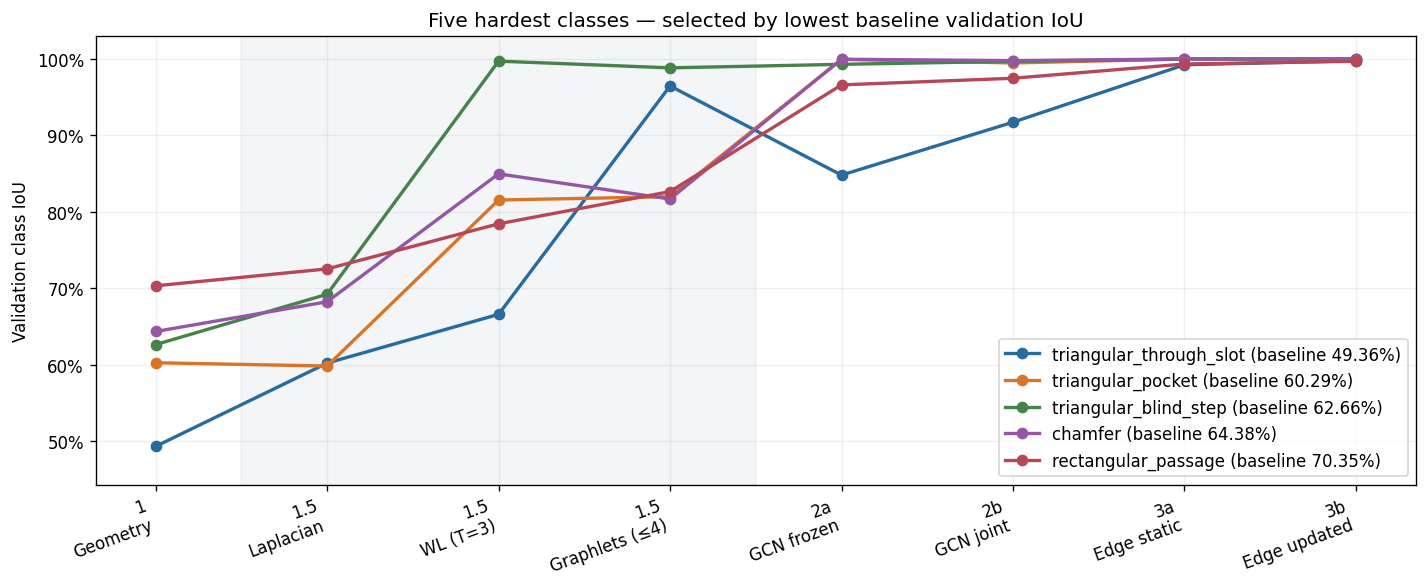

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for color, row in zip(colors, hardest.itertuples(index=False)):
    values = iou_table.loc[row.class_index, model_order].to_numpy(dtype=float)
    ax.plot(x, values, marker="o", linewidth=2,
            label=f"{row.class_name} (baseline {row.iou:.2%})", color=color)
ax.axvspan(0.5, 3.5, color="#718096", alpha=0.08)
lowest = min(hardest["iou"].min(), iou_table.loc[hardest["class_index"], model_order].min().min())
ax.set_ylim(max(0, lowest - 0.05), 1.03)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xticks(x, axis_labels, rotation=20, ha="right")
ax.set_ylabel("Validation class IoU")
ax.set_title("Five hardest classes — selected by lowest baseline validation IoU")
ax.grid(alpha=0.2)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(output_dir / "baseline_top5_iou_focus.png", dpi=180, bbox_inches="tight")
plt.show()


## Reading these comparisons

The shallow alternatives measure how much explicit topology can add to frozen geometry. Stages 2a and 2b compare learned message passing with frozen versus joint geometry. Stage 3 adds curve geometry and gated messages; updated edges also add endpoint conditioning. Architecture, capacity and training differ, so successive gains are descriptive evidence rather than isolated causal effects. These are single-run validation results; near saturation motivates inspecting individual error cases, not claiming perfect generalization.

All computed tables, plots and input-file hashes are saved in `results/result_analysis/`. The cached row identity supports a later sample-by-sample error analysis without training or inference.

In [8]:
baseline_misses = int(summary.loc["Geometry", "misclassified_faces"])
top5_misses = int(hardest["false_negative"].sum())
print(f"The five lowest-baseline-IoU classes account for {top5_misses:,}/{baseline_misses:,} "
      f"missed validation faces ({top5_misses / baseline_misses:.1%}).")
for model_name in ("GCN frozen", "GCN joint", "Edge static", "Edge updated"):
    row = summary.loc[model_name]
    print(f"{model_name}: mean IoU {row['mean_iou']:.2%}; "
          f"{int(row['misclassified_faces']):,} misclassified validation faces.")
print("Baseline difficulty and residual graphlet difficulty can select different classes; "
      "inspect the rectangular-through-step case separately below.")


The five lowest-baseline-IoU classes account for 4,630/7,420 missed validation faces (62.4%).
GCN frozen: mean IoU 98.21%; 637 misclassified validation faces.
GCN joint: mean IoU 98.93%; 342 misclassified validation faces.
Edge static: mean IoU 99.87%; 37 misclassified validation faces.
Edge updated: mean IoU 99.93%; 18 misclassified validation faces.
Baseline difficulty and residual graphlet difficulty can select different classes; inspect the rectangular-through-step case separately below.


## Additional case: rectangular through step

This class is selected separately because it remains difficult for graphlets, not because it belongs to the baseline's top five. Show its baseline rank, graphlet rank and class IoU through the same model ladder. Class ranks use lowest IoU first, with ties broken by class index.


rectangular_through_step: baseline difficulty rank 7; graphlet difficulty rank 1 (rank 1 = lowest class IoU).


,stage,support,iou,recall,false_negative,false_positive
model,,,,,,
Geometry,1,2883,71.27%,78.98%,606,312
Laplacian,1.5,2883,72.31%,78.63%,616,252
WL (T=3),1.5,2883,72.35%,83.04%,489,426
Graphlets (≤4),1.5,2883,76.63%,84.50%,447,296
GCN frozen,2a,2883,99.76%,99.93%,2,5
GCN joint,2b,2883,99.69%,99.83%,5,4
Edge static,3a,2883,100.00%,100.00%,0,0
Edge updated,3b,2883,100.00%,100.00%,0,0


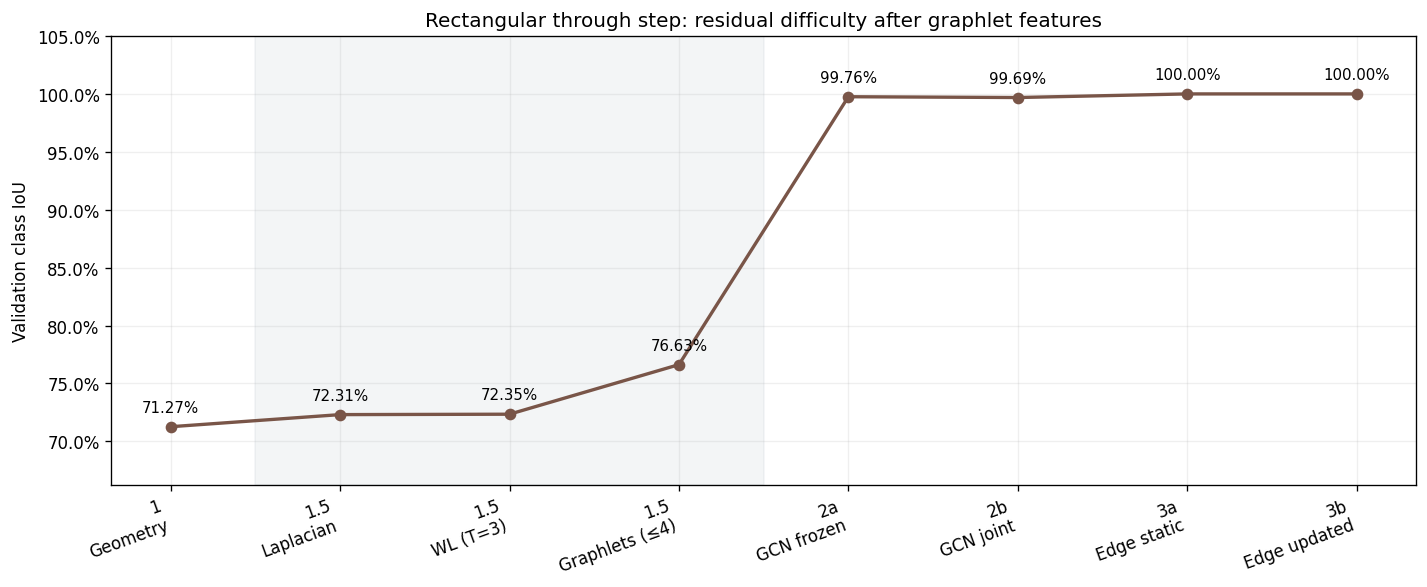

In [9]:
case_name = "rectangular_through_step"
case_index = next(index for index, name in class_names.items() if name == case_name)
def difficulty_rank(model_name, class_index):
    ordered = class_metrics[class_metrics["model"] == model_name].sort_values(
        ["iou", "class_index"], ascending=[True, True])["class_index"].tolist()
    return ordered.index(class_index) + 1

print(f"{case_name}: baseline difficulty rank {difficulty_rank('Geometry', case_index)}; "
      f"graphlet difficulty rank {difficulty_rank('Graphlets (≤4)', case_index)} "
      "(rank 1 = lowest class IoU).")
case_metrics = class_metrics[class_metrics["class_index"] == case_index].set_index("model").loc[model_order]
display(case_metrics[["stage", "support", "iou", "recall", "false_negative", "false_positive"]]
        .style.format({"iou": "{:.2%}", "recall": "{:.2%}"}))
case_metrics.to_csv(output_dir / "rectangular_through_step_metrics.csv")
fig, ax = plt.subplots(figsize=(12, 5))
values = case_metrics["iou"].to_numpy()
ax.plot(x, values, color="#795548", marker="o", linewidth=2)
for i, value in zip(x, values):
    ax.annotate(f"{value:.2%}", (i, value), xytext=(0, 9),
                textcoords="offset points", ha="center", fontsize=9)
ax.axvspan(0.5, 3.5, color="#718096", alpha=0.08)
ax.set_ylim(max(0, values.min() - 0.05), 1.05)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xticks(x, axis_labels, rotation=20, ha="right")
ax.set_ylabel("Validation class IoU")
ax.set_title("Rectangular through step: residual difficulty after graphlet features")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "rectangular_through_step_iou_ladder.png", dpi=180, bbox_inches="tight")
plt.show()


## Class difficulty rank across the ladder

Show **all machining-feature classes except stock**, each with its own colour. Rank within these 15 classes for each model by validation IoU: **rank 1 is lowest IoU (hardest)**. Exact IoU ties share their average rank, avoiding arbitrary ordering when several classes reach 100%.

Rank is relative: a class can become the hardest while its absolute IoU improves, if other classes improve more. Stage 1.5 entries remain parallel alternatives. The accompanying tables show ranks and absolute IoU for all included classes. Stock is excluded only from this rank analysis, not from the overall metrics or earlier tables.


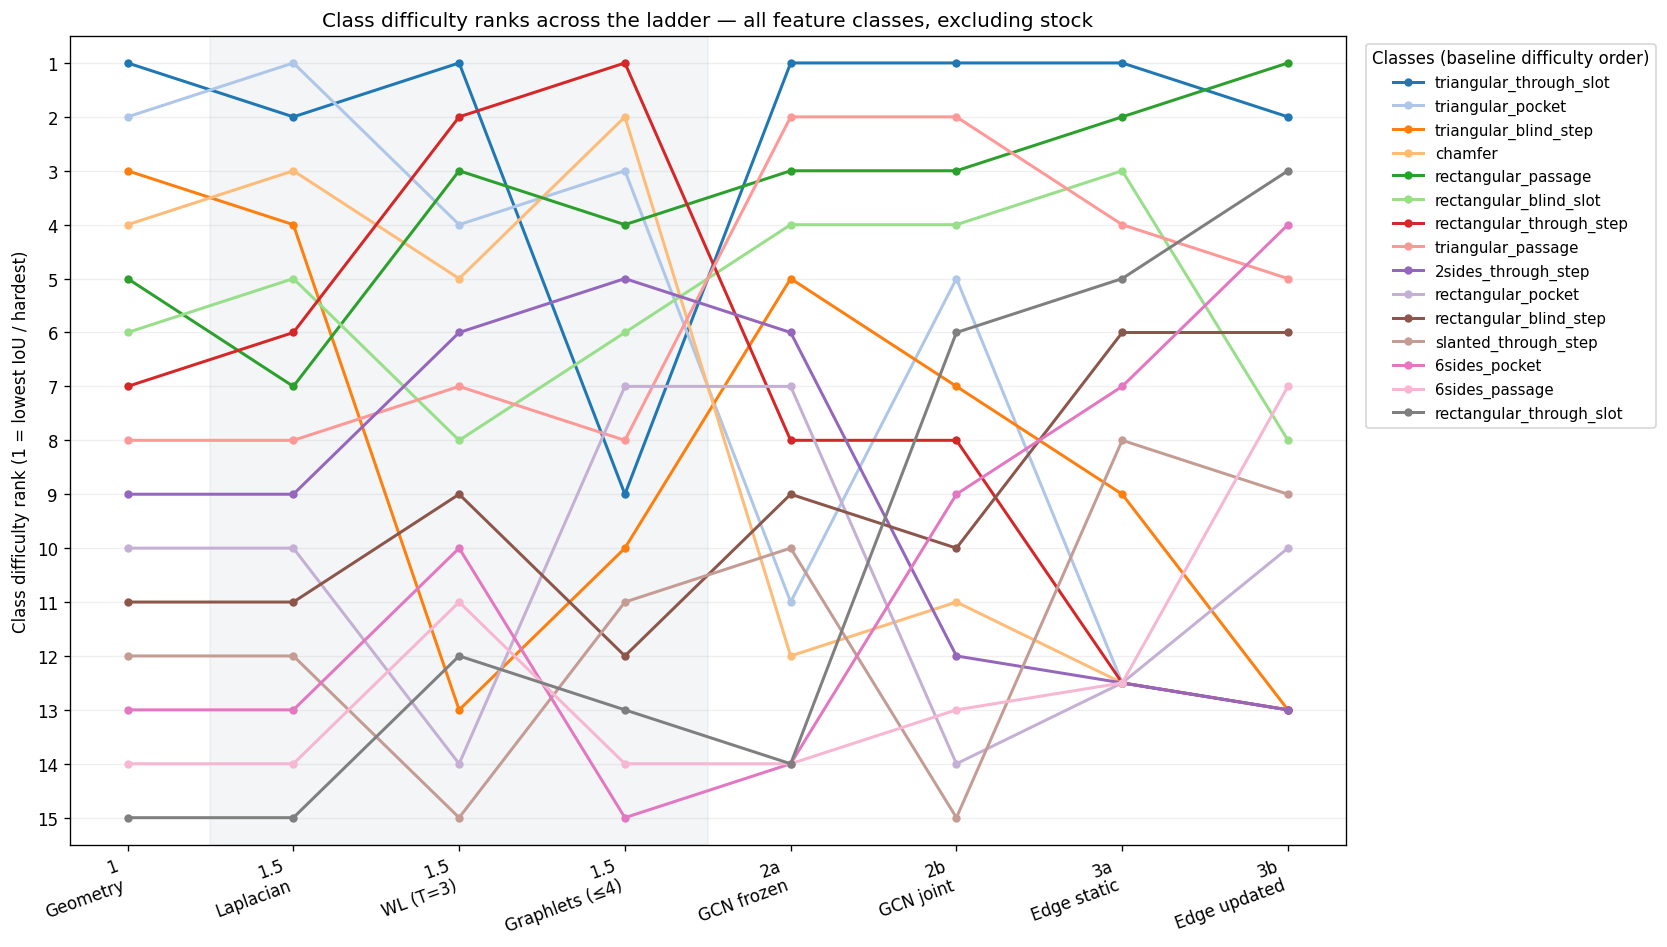

Difficulty ranks excluding stock (average ranks for exact IoU ties):


model,class_name,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
class_index,,,,,,,,,
1,triangular_through_slot,1.0,2.0,1.0,9.0,1.0,1.0,1.0,2.0
12,triangular_pocket,2.0,1.0,4.0,3.0,11.0,5.0,12.5,13.0
9,triangular_blind_step,3.0,4.0,13.0,10.0,5.0,7.0,9.0,13.0
14,chamfer,4.0,3.0,5.0,2.0,12.0,11.0,12.5,13.0
2,rectangular_passage,5.0,7.0,3.0,4.0,3.0,3.0,2.0,1.0
10,rectangular_blind_slot,6.0,5.0,8.0,6.0,4.0,4.0,3.0,8.0
5,rectangular_through_step,7.0,6.0,2.0,1.0,8.0,8.0,12.5,13.0
3,triangular_passage,8.0,8.0,7.0,8.0,2.0,2.0,4.0,5.0
6,2sides_through_step,9.0,9.0,6.0,5.0,6.0,12.0,12.5,13.0


Absolute validation IoU for the same classes:


,class_name,validation_faces,baseline_missed_faces,Geometry,Laplacian,WL (T=3),Graphlets (≤4),GCN frozen,GCN joint,Edge static,Edge updated
class_index,,,,,,,,,,,
1,triangular_through_slot,2985,1245,49.36%,60.25%,66.62%,96.47%,84.82%,91.73%,99.23%,99.77%
12,triangular_pocket,3816,975,60.29%,59.86%,81.56%,82.00%,99.95%,99.48%,100.00%,100.00%
9,triangular_blind_step,3828,859,62.66%,69.24%,99.71%,98.84%,99.30%,99.69%,99.97%,100.00%
14,chamfer,2763,746,64.38%,68.26%,84.98%,81.69%,99.96%,99.78%,100.00%,100.00%
2,rectangular_passage,4390,805,70.35%,72.56%,78.45%,82.66%,96.61%,97.48%,99.34%,99.70%
10,rectangular_blind_slot,4645,501,70.77%,71.77%,92.98%,88.03%,98.68%,99.44%,99.85%,99.96%
5,rectangular_through_step,2883,606,71.27%,72.31%,72.35%,76.63%,99.76%,99.69%,100.00%,100.00%
3,triangular_passage,6804,763,76.05%,80.24%,85.64%,93.81%,93.21%,96.96%,99.85%,99.91%
6,2sides_through_step,1804,258,78.56%,82.90%,85.31%,86.43%,99.61%,99.83%,100.00%,100.00%


In [10]:
rank_indices = [i for i in iou_table.index if class_names[i].lower() != "stock"]
rank_iou = iou_table.loc[rank_indices, model_order]
difficulty_ranks = rank_iou.rank(axis=0, method="average", ascending=True)
# Keep colour/legend order fixed by baseline difficulty.
rank_order = rank_iou.sort_values("Geometry").index.tolist()
palette = plt.get_cmap("tab20")
fig, ax = plt.subplots(figsize=(14, 8))
for position, class_index in enumerate(rank_order):
    ax.plot(x, difficulty_ranks.loc[class_index, model_order], marker="o",
            linewidth=1.8, markersize=4, color=palette(position),
            label=class_names[class_index])
ax.axvspan(0.5, 3.5, color="#718096", alpha=0.08)
ax.set_xticks(x, axis_labels, rotation=20, ha="right")
ax.set_yticks(range(1, len(rank_indices) + 1))
ax.set_ylim(len(rank_indices) + 0.5, 0.5)
ax.set_ylabel("Class difficulty rank (1 = lowest IoU / hardest)")
ax.set_title("Class difficulty ranks across the ladder — all feature classes, excluding stock")
ax.grid(axis="y", alpha=0.2)
ax.legend(title="Classes (baseline difficulty order)", loc="upper left",
          bbox_to_anchor=(1.01, 1), fontsize=9)
fig.tight_layout()
fig.savefig(output_dir / "class_difficulty_rank_ladder.png", dpi=180, bbox_inches="tight")
plt.show()

rank_table = difficulty_ranks.loc[rank_order, model_order].copy()
rank_table.insert(0, "class_name", [class_names[i] for i in rank_table.index])
print("Difficulty ranks excluding stock (average ranks for exact IoU ties):")
display(rank_table.style.format({model: "{:.1f}" for model in model_order}))
print("Absolute validation IoU for the same classes:")
display(class_iou_table.loc[rank_order].style.format({model: "{:.2%}" for model in model_order})
        .background_gradient(cmap=table_cmap, subset=model_order, axis=None,
                             vmin=iou_table.min().min(), vmax=iou_table.max().max()))
rank_table.to_csv(output_dir / "class_difficulty_ranks.csv")
